# **¿Qué porcentaje de la facturación comercial de los equipos depende actualmente de firmas de apuestas, y cuál sería el impacto financiero estimado ante una eventual prohibición o restricción regulatoria estatal?**

In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [65]:
url = "https://raw.githubusercontent.com/Geralf21/Analisis_Patrocinios_Clubes_Brasileros/refs/heads/main/BaseDatos/balances_y_sponsors_2019_2025.csv"
df = pd.read_csv(url,  thousands=',')
df.head(7)


,club,año,ingreso_operativo_bruto,ingreso_recurrente,ingreso_comercial_total,patrocinio_uniforme,sponsor_bet_principal,tipo_presencia_bet,ingreso_sponsor_bet,contrato_bet_anualizado,pasivo_derechos_imagen,pasivo_circulante,superavit_o_deficit
0,Palmeiras,2019,641.92,533.70,134.36,89.13,Nenhum,Sin Bet,0.0,0.0,39.57,252.46,1.72
1,Palmeiras,2020,558.73,410.14,132.98,115.02,Nenhum,Sin Bet,0.0,0.0,46.69,359.50,-151.02
2,Palmeiras,2021,972.57,833.42,198.44,86.00,Nenhum,Sin Bet,0.0,0.0,30.19,308.76,123.42
3,Palmeiras,2022,856.07,682.27,164.23,85.90,Nenhum,Sin Bet,0.0,0.0,29.41,328.15,18.21
4,Palmeiras,2023,908.91,721.91,162.76,91.43,Nenhum,Sin Bet,0.0,0.0,35.17,532.35,8.53
5,Palmeiras,2024,1274.15,1068.87,188.79,99.95,Esportes da Sorte / Sportingbet,Secundario / Transición,18.5,81.0,37.97,750.84,198.18
6,Palmeiras,2025,1700.00,1259.65,248.87,121.55,Sportingbet,Máster Principal,100.0,100.0,55.45,653.31,292.40


In [66]:
df.tail(7)

,club,año,ingreso_operativo_bruto,ingreso_recurrente,ingreso_comercial_total,patrocinio_uniforme,sponsor_bet_principal,tipo_presencia_bet,ingreso_sponsor_bet,contrato_bet_anualizado,pasivo_derechos_imagen,pasivo_circulante,superavit_o_deficit
48,Fluminense,2019,265.20,159.78,14.70,9.35,Nenhum,Sin Bet,0.0,0.0,13.67,201.20,-9.30
49,Fluminense,2020,194.31,143.98,20.32,9.77,Nenhum,Sin Bet,0.0,0.0,17.41,275.16,-2.92
50,Fluminense,2021,333.63,224.04,28.86,20.10,Betano,Secundario / Transición,7.5,7.5,15.80,306.81,-2.06
51,Fluminense,2022,347.24,253.31,54.82,32.55,Betano,Secundario / Transición,15.0,15.0,12.50,324.50,7.03
52,Fluminense,2023,474.78,245.17,106.41,49.63,Betano,Secundario / Transición,20.0,20.0,8.20,388.90,78.70
53,Fluminense,2024,684.18,416.01,148.13,78.27,Superbet,Máster Principal,42.0,52.0,6.35,412.30,0.11
54,Fluminense,2025,1022.44,789.07,138.02,78.34,Superbet,Máster Principal,52.5,52.5,4.28,469.98,51.59


Creamos las columnas derivadas en porcentajes para que se vea la importancia y peso que tienen los sponsors de casas deportivas en relacion a todos los ingresos comerciales.

In [67]:
# Creo columnas derivadas
df['pctj_bets_comercial'] = (df['ingreso_sponsor_bet'] / df['ingreso_comercial_total']) * 100

df['resultado_sin_bets'] = df['superavit_o_deficit'] - df['ingreso_sponsor_bet']



Grafico de El porcentaje de dependencia de las casas de apuestas en los clubes  en el 2025 es llamativo , con una dependencia de mas del 40% sobre el total de sus ingresos comerciales.

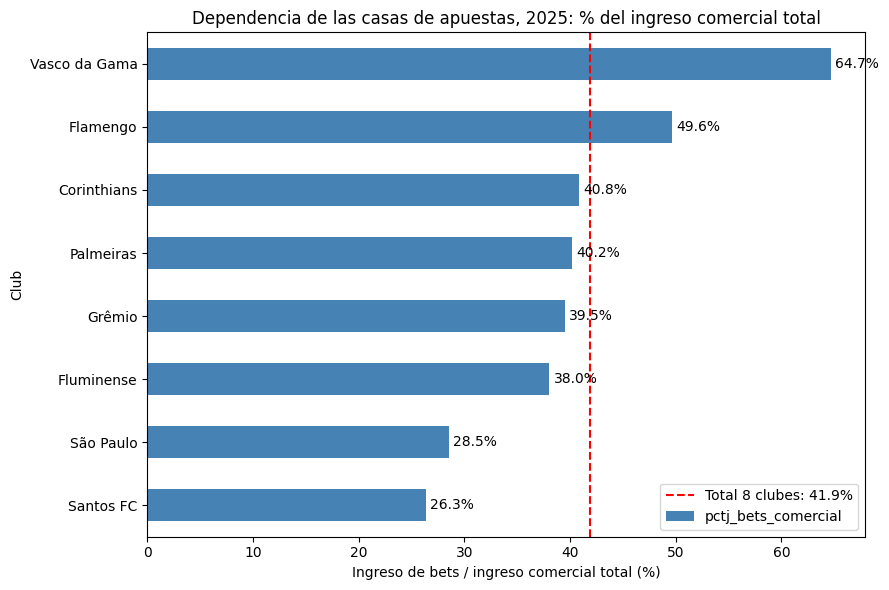

In [68]:
df_2025 = df[df["año"] == 2025].copy()
df_2025 = df_2025.sort_values("pctj_bets_comercial")

ax = df_2025.plot(kind="barh", x="club", y="pctj_bets_comercial",
                  legend=False, figsize=(9, 6), color="steelblue")

# Línea con la dependencia del conjunto de clubes (promedio ponderado)
total = df_2025["ingreso_sponsor_bet"].sum() / df_2025["ingreso_comercial_total"].sum() * 100
ax.axvline(total, color="red", linestyle="--", label=f"Total 8 clubes: {total:.1f}%")

ax.set_title("Dependencia de las casas de apuestas, 2025: % del ingreso comercial total")
ax.set_xlabel("Ingreso de bets / ingreso comercial total (%)")
ax.set_ylabel("Club")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.legend()
plt.tight_layout()
plt.savefig("dependencia_bets_2025.png", dpi=150)
plt.show()

Tabla de apoyo que muestra el impacto de la eliminacion de las casas de apuestas  a sus superavit / deficit

In [69]:
df_2025[["club", "superavit_o_deficit", "resultado_sin_bets"]]

,club,superavit_o_deficit,resultado_sin_bets
47,Santos FC,-79.40,-116.90
20,São Paulo,56.98,-7.02
54,Fluminense,51.59,-0.91
27,Grêmio,35.48,-7.02
6,Palmeiras,292.40,192.40
13,Corinthians,139.00,36.00
34,Flamengo,336.00,67.50
40,Vasco da Gama,81.22,11.22


Grafico de los  Resultados de los clubes en 2025 si hubieran prohibido las casas de apuestas,  , algunos rozan o llegan al deficit total. (Santos estaba en deficit y fue a peor deficit )

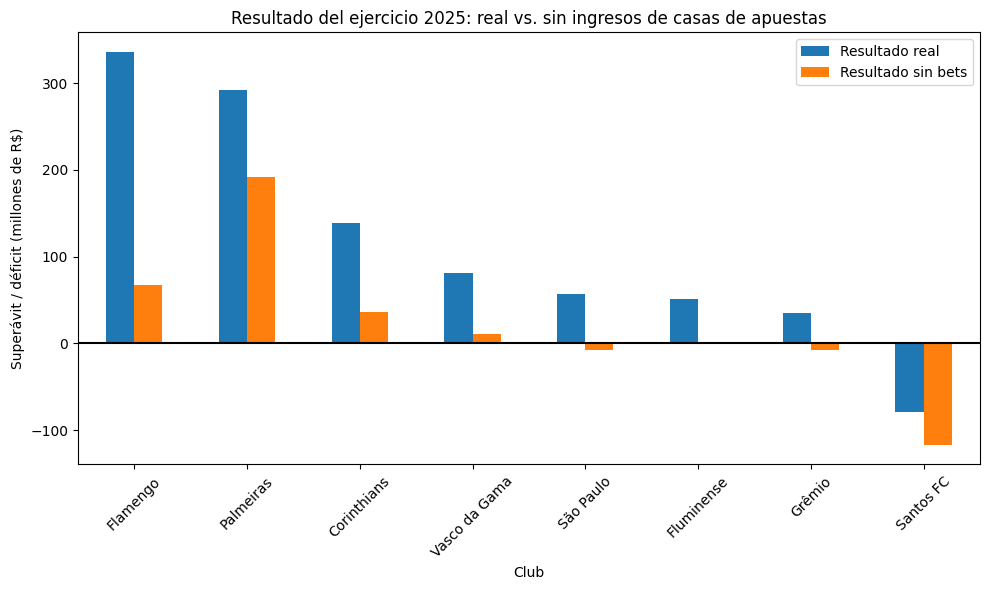

In [70]:
df_2025 = df_2025.sort_values("superavit_o_deficit", ascending=False)

tabla = df_2025[["club", "superavit_o_deficit", "resultado_sin_bets"]].copy()
tabla.columns = ["club", "Resultado real", "Resultado sin bets"]

tabla.plot(x="club", kind="bar", figsize=(10, 6))

plt.axhline(0, color="black")
plt.title("Resultado del ejercicio 2025: real vs. sin ingresos de casas de apuestas")
plt.xlabel("Club")
plt.ylabel("Superávit / déficit (millones de R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("resultado_sin_bets_2025.png", dpi=150)
plt.show()

Tabla de apoyo de Clubes con superavit positivo y como les impactaria si se prohiben las casas de apuestas deportivas , porcentualmente hablando

In [71]:
#Clubes con superavit positivo (excluyo santos)
df_2025_pos = df_2025[df_2025["superavit_o_deficit"] > 0].copy()

# Porecentaje de caida del superavit
df_2025_pos["caida_superavit_pct"] = df_2025_pos["ingreso_sponsor_bet"] / df_2025_pos["superavit_o_deficit"] * 100

df_2025_pos = df_2025_pos.sort_values("caida_superavit_pct")

# Tabla
df_2025_pos[["club", "superavit_o_deficit", "resultado_sin_bets", "caida_superavit_pct"]]

,club,superavit_o_deficit,resultado_sin_bets,caida_superavit_pct
6,Palmeiras,292.40,192.40,34.199726
13,Corinthians,139.00,36.00,74.100719
34,Flamengo,336.00,67.50,79.910714
40,Vasco da Gama,81.22,11.22,86.185669
54,Fluminense,51.59,-0.91,101.763908
20,São Paulo,56.98,-7.02,112.320112
27,Grêmio,35.48,-7.02,119.785795


Grafico que indica  los Clubes por encima del 100% , son los clubes que entrarian en Deficit.

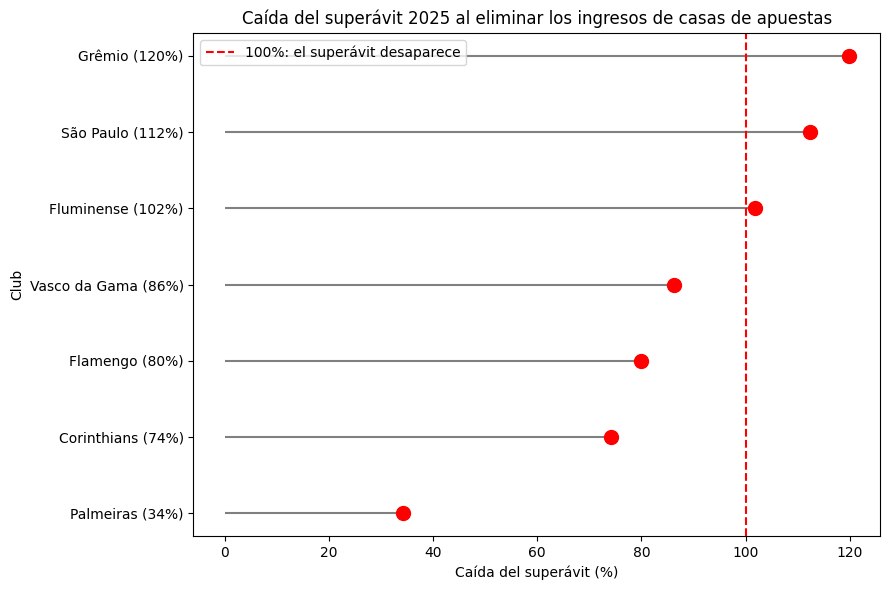

In [72]:

# Etiqueta con el club y su porcentaje (sin usar for)
df_2025_pos["etiqueta"] = (df_2025_pos["club"] + " ("
                           + df_2025_pos["caida_superavit_pct"].round(0).astype(int).astype(str) + "%)")

plt.figure(figsize=(9, 6))

plt.hlines(y=df_2025_pos["etiqueta"], xmin=0, xmax=df_2025_pos["caida_superavit_pct"], color="gray")
plt.plot(df_2025_pos["caida_superavit_pct"], df_2025_pos["etiqueta"], "o", markersize=10, color="red")

plt.axvline(100, color="red", linestyle="--", label="100%: el superávit desaparece")

plt.title("Caída del superávit 2025 al eliminar los ingresos de casas de apuestas")
plt.xlabel("Caída del superávit (%)")
plt.ylabel("Club")
plt.legend()
plt.tight_layout()
plt.savefig("caida_superavit_lollipop_2025.png", dpi=150)
plt.show()

In [73]:
df_2019 = df[df["año"] == 2019].copy()




Grafico de la Presencia de las casas de apuestas a los largo de los años ( menos a más )

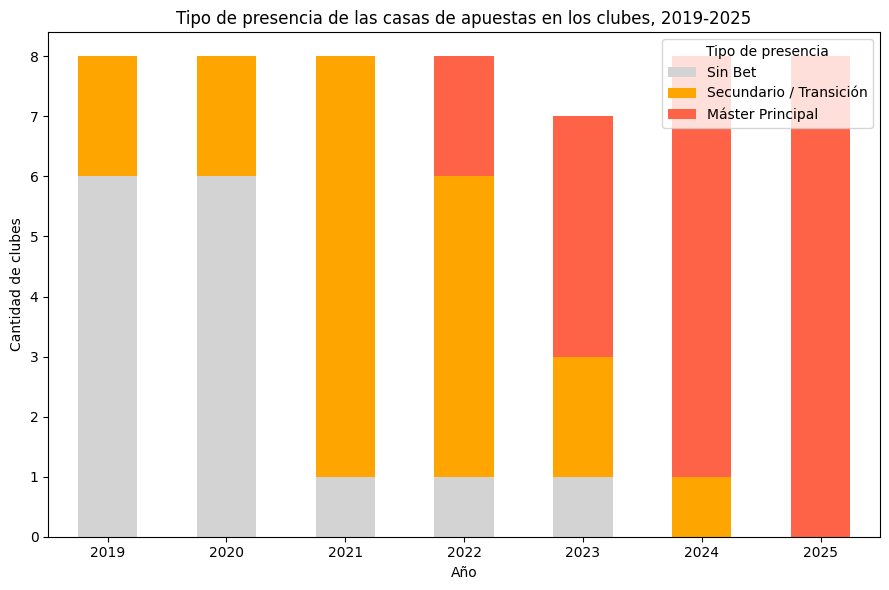

In [74]:
tabla = pd.crosstab(df["año"], df["tipo_presencia_bet"])
tabla = tabla[["Sin Bet", "Secundario / Transición", "Máster Principal"]]

tabla.plot(kind="bar", stacked=True, figsize=(9, 6), color=["lightgray", "orange", "tomato"])

plt.title("Tipo de presencia de las casas de apuestas en los clubes, 2019-2025")
plt.xlabel("Año")
plt.ylabel("Cantidad de clubes")
plt.xticks(rotation=0)
plt.legend(title="Tipo de presencia")
plt.tight_layout()
plt.savefig("tipo_presencia_por_anio.png", dpi=150)
plt.show()

Tabla de apoyo que nos muestra que en 2019 cuando no habia tanto peso de las casas de apuestas habian clubes en superavit y en deficit ( como en 2025 y la actualidad )

In [75]:
df_2019 = df[df["año"] == 2019]
df_2019[["club", "tipo_presencia_bet", "ingreso_sponsor_bet", "superavit_o_deficit"]]

,club,tipo_presencia_bet,ingreso_sponsor_bet,superavit_o_deficit
0,Palmeiras,Sin Bet,0.0,1.72
7,Corinthians,Secundario / Transición,4.5,-195.50
14,São Paulo,Secundario / Transición,3.0,-156.15
21,Grêmio,Sin Bet,0.0,22.19
28,Flamengo,Sin Bet,0.0,62.92
35,Vasco da Gama,Sin Bet,0.0,-5.00
41,Santos FC,Sin Bet,0.0,23.50
48,Fluminense,Sin Bet,0.0,-9.30


Grafico del 2019 que muestra que hay clubes tanto en deficit como en superavit cuando las apuestas no tenian tanto peso como en 2025 y la actualidad

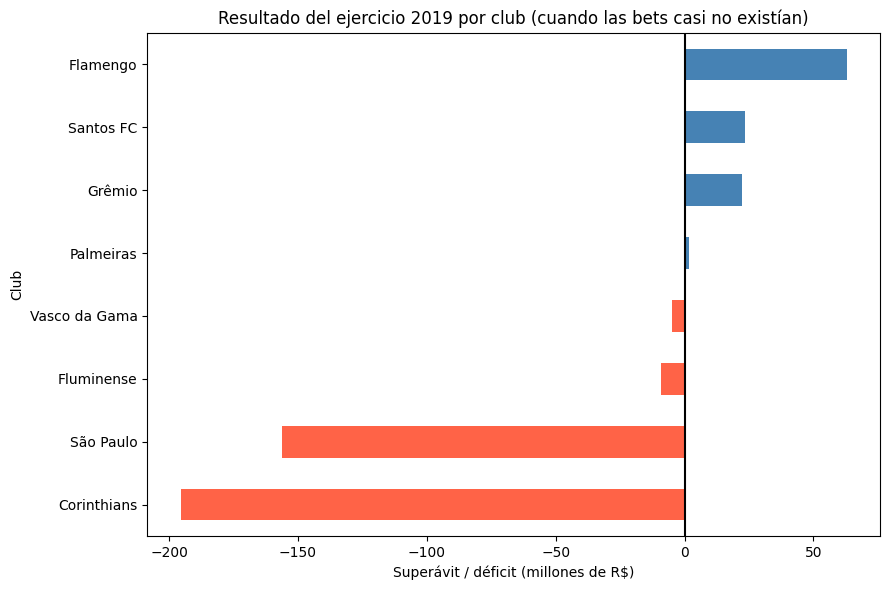

In [76]:
# Datos de 2019
df_2019 = df[df["año"] == 2019].copy()
df_2019 = df_2019.sort_values("superavit_o_deficit")

# Azul si terminó con superávit, rojo si terminó con déficit
colores = np.where(df_2019["superavit_o_deficit"] > 0, "steelblue", "tomato")

df_2019.plot(x="club", y="superavit_o_deficit", kind="barh", figsize=(9, 6),
             color=colores, legend=False)

plt.axvline(0, color="black")
plt.title("Resultado del ejercicio 2019 por club (cuando las bets casi no existían)")
plt.xlabel("Superávit / déficit (millones de R$)")
plt.ylabel("Club")
plt.tight_layout()
plt.savefig("superavit_2019.png", dpi=150)
plt.show()

El peso de las casas de apuestas sobre los ingresos comerciales en 2019 comparado con 2025 (notamos que en 2019 solo dos clubes tenian peso minimo de casas de apuestas sobre sus ingresos comerciales totales )

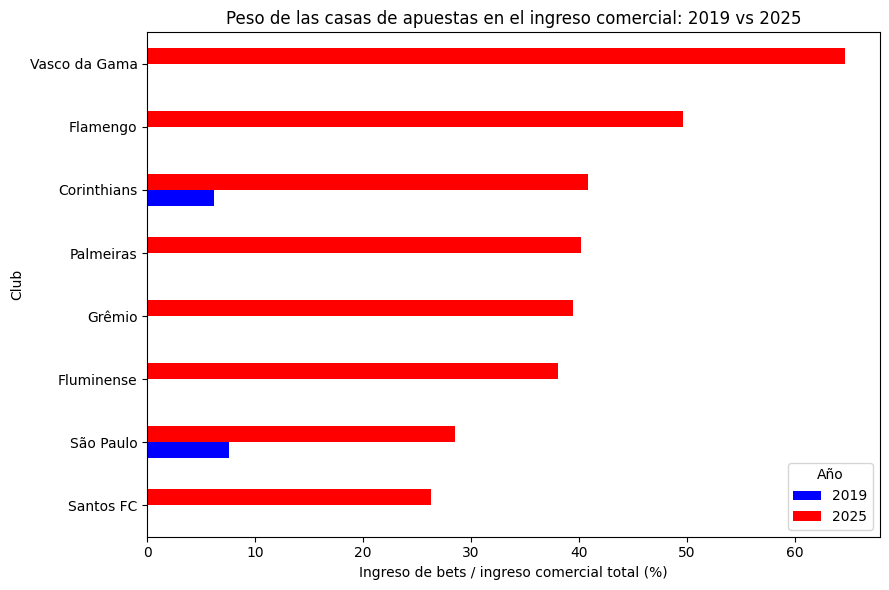

In [77]:
# Tabla con el % de bets sobre el ingreso comercial en 2019 y 2025
comparacion = df[df["año"].isin([2019, 2025])].pivot(index="club", columns="año", values="pctj_bets_comercial")
comparacion = comparacion.sort_values(2025)

comparacion.plot(kind="barh", figsize=(9, 6), color=["blue", "red"])

plt.title("Peso de las casas de apuestas en el ingreso comercial: 2019 vs 2025")
plt.xlabel("Ingreso de bets / ingreso comercial total (%)")
plt.ylabel("Club")
plt.legend(title="Año")
plt.tight_layout()
plt.savefig("dependencia_2019_vs_2025.png", dpi=150)
plt.show()

CONCLUSION : La conclusion que llegamos es que ante una posible o ya realidad de la prohibicion de las apuestas deportivas en el Brasileirao, todos los clubes analizados sufriran perdidas en sus ingresos ya que las casas de apuestas les representan un gran porcentaje en sus ingresos comerciales. Sin embargo, pudimos notar que si esto ya es una realidad... , no es un escenario desconcido para los clubes. En años anteriores  los clubes se arreglaban para mantenerse y habia tanto clubes en supervit como en deficit, como ahora.